In [31]:
# ============================================================
# 07 - DEEP LEARNING (Neural Network with sklearn MLP)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)
import sys
import os

sys.path.append(os.path.abspath(".."))

from src.data.load_master_data import load_master_data

df = load_master_data()

print(f"Shape: {df.shape}")
display(df.head())

Shape: (25939, 46)


,season,round,driver_id,driver_name,constructor_id,grid,position,points,laps,status,...,podium,win,pole_position,front_row,weighted_points_at_circuit,driver_circuit_delta,points_last_5_races,current_season_points,avg_points_per_season,constructor_points_current_season
0,1950,1,farina,Nino Farina,alfa,1,1,9.0,70,Finished,...,1,1,1,1,0.0,0.0,0.0,0.0,0.0,0.0
1,1950,1,fagioli,Luigi Fagioli,alfa,2,2,6.0,70,Finished,...,1,0,0,1,0.0,0.0,0.0,0.0,0.0,0.0
2,1950,1,reg_parnell,Reg Parnell,alfa,4,3,4.0,70,Finished,...,1,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,1950,1,cabantous,Yves Cabantous,lago,6,4,3.0,68,+2 Laps,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
4,1950,1,rosier,Louis Rosier,lago,9,5,2.0,68,+2 Laps,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [32]:
# ============================================================
# SAMME FEATURES SOM NOTEBOOK 04
# ============================================================

final_features = [
    "q1_seconds", "q2_seconds", "q3_seconds",
    "weighted_points_at_circuit", "driver_circuit_delta",
    "grid", "driver_age", "current_season_points",
    "avg_points_per_season", "points_last_5_races",
    "front_row", "constructor_name", "driver_nationality"
]

target = "podium"

# Konverter kategoriske kolonner
df_model = df.copy()

for col in final_features:
    if df_model[col].dtype.name == "category":
        df_model[col] = df_model[col].astype(str)

# One-hot encode kategoriske kolonner
df_encoded = pd.get_dummies(
    df_model[final_features],
    columns=["constructor_name", "driver_nationality"]
)

print(f"Features etter encoding: {df_encoded.shape[1]}")

Features etter encoding: 256


In [33]:
# ============================================================
# KRONOLOGISK SPLIT
# Samme tilnærming som notebook 04
# ============================================================

split_season = 2022

train_mask = df["season"] < split_season
test_mask = df["season"] >= split_season

X_train = df_encoded[train_mask].fillna(0).values
X_test = df_encoded[test_mask].fillna(0).values

y_train = df[target][train_mask].values
y_test = df[target][test_mask].values

print(f"Treningsett: {X_train.shape}")
print(f"Testsett: {X_test.shape}")
print(f"Podium-rate treningsett: {y_train.mean():.2%}")
print(f"Podium-rate testsett: {y_test.mean():.2%}")

Treningsett: (24035, 256)
Testsett: (1904, 256)
Podium-rate treningsett: 13.28%
Podium-rate testsett: 14.97%


In [34]:
# ============================================================
# SKALER DATA
# Nevrale nettverk er svært sensitive for skala
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Snitt etter skalering (skal være ~0):", X_train_scaled.mean().round(3))
print("Std etter skalering (skal være ~1):", X_train_scaled.std().round(3))

Snitt etter skalering (skal være ~0): -0.0
Std etter skalering (skal være ~1): 0.992


In [35]:
model_nn = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
    tol=1e-5,
    random_state=42,
    verbose=True
)

model_nn.fit(X_train_scaled, y_train)

print(f"\nAntall epochs trent: {model_nn.n_iter_}")
print(f"Beste validation score: {model_nn.best_validation_score_:.4f}")

Iteration 1, loss = 0.30713425
Validation score: 0.883527
Iteration 2, loss = 0.25312847
Validation score: 0.881032
Iteration 3, loss = 0.24576395
Validation score: 0.880200
Iteration 4, loss = 0.24297940
Validation score: 0.878952
Iteration 5, loss = 0.24061361
Validation score: 0.880616
Iteration 6, loss = 0.23814168
Validation score: 0.879784
Iteration 7, loss = 0.23573990
Validation score: 0.880616
Iteration 8, loss = 0.23465015
Validation score: 0.877704
Iteration 9, loss = 0.23271632
Validation score: 0.876456
Iteration 10, loss = 0.23124550
Validation score: 0.877704
Iteration 11, loss = 0.22997487
Validation score: 0.877288
Iteration 12, loss = 0.22905029
Validation score: 0.878536
Iteration 13, loss = 0.22620140
Validation score: 0.880200
Iteration 14, loss = 0.22599515
Validation score: 0.877288
Iteration 15, loss = 0.22433320
Validation score: 0.876040
Iteration 16, loss = 0.22328767
Validation score: 0.877288
Iteration 17, loss = 0.22153300
Validation score: 0.873960
Iterat

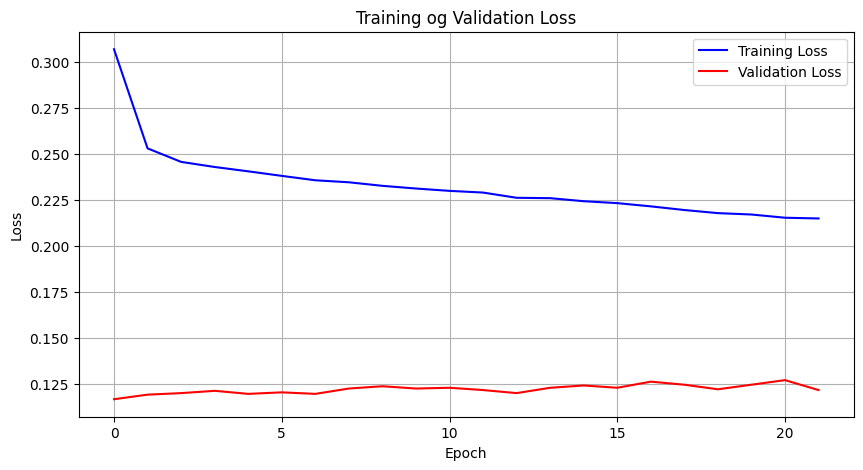

In [36]:
# ============================================================
# VISUALISER TRENINGSHISTORIKK
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(model_nn.loss_curve_, label="Training Loss", color="blue")

if hasattr(model_nn, "validation_scores_"):
    plt.plot(
        [1 - s for s in model_nn.validation_scores_],
        label="Validation Loss",
        color="red"
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training og Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [37]:
# ============================================================
# EVALUER MED STANDARD TERSKEL (0.5)
# ============================================================

y_pred_05 = model_nn.predict(X_test_scaled)

print("=== STANDARD TERSKEL (0.5) ===")
print(classification_report(y_test, y_pred_05))

=== STANDARD TERSKEL (0.5) ===
              precision    recall  f1-score   support

           0       0.93      0.95      0.94      1619
           1       0.67      0.62      0.65       285

    accuracy                           0.90      1904
   macro avg       0.80      0.79      0.79      1904
weighted avg       0.90      0.90      0.90      1904



Beste terskel: 0.40
Beste F1: 0.6791


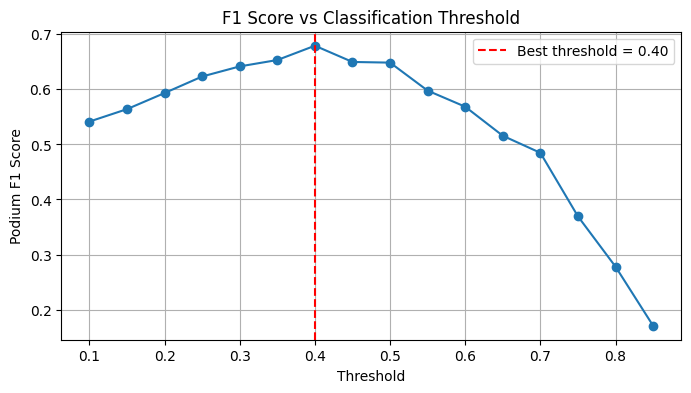

In [38]:
# ============================================================
# OPTIMALISER TERSKEL
#
# I stedet for å gjette 0.5 eller 0.7,
# finn den terskelen som gir best F1 for podium
# ============================================================

from sklearn.metrics import f1_score

y_prob = model_nn.predict_proba(X_test_scaled)[:, 1]

thresholds = np.arange(0.1, 0.9, 0.05)
f1_scores = []

for thresh in thresholds:
    preds = (y_prob > thresh).astype(int)
    f1 = f1_score(y_test, preds)
    f1_scores.append(f1)

best_threshold = thresholds[np.argmax(f1_scores)]
best_f1 = max(f1_scores)

print(f"Beste terskel: {best_threshold:.2f}")
print(f"Beste F1: {best_f1:.4f}")

# Plot terskel vs F1
plt.figure(figsize=(8, 4))
plt.plot(thresholds, f1_scores, marker="o")
plt.axvline(x=best_threshold, color="red", linestyle="--", label=f"Best threshold = {best_threshold:.2f}")
plt.xlabel("Threshold")
plt.ylabel("Podium F1 Score")
plt.title("F1 Score vs Classification Threshold")
plt.legend()
plt.grid(True)
plt.show()

In [39]:
# ============================================================
# EVALUER MED OPTIMAL TERSKEL
# ============================================================

y_pred_best = (y_prob > best_threshold).astype(int)

print(f"=== OPTIMAL TERSKEL ({best_threshold:.2f}) ===")
print(classification_report(y_test, y_pred_best))

=== OPTIMAL TERSKEL (0.40) ===
              precision    recall  f1-score   support

           0       0.96      0.91      0.93      1619
           1       0.61      0.76      0.68       285

    accuracy                           0.89      1904
   macro avg       0.78      0.84      0.81      1904
weighted avg       0.90      0.89      0.90      1904



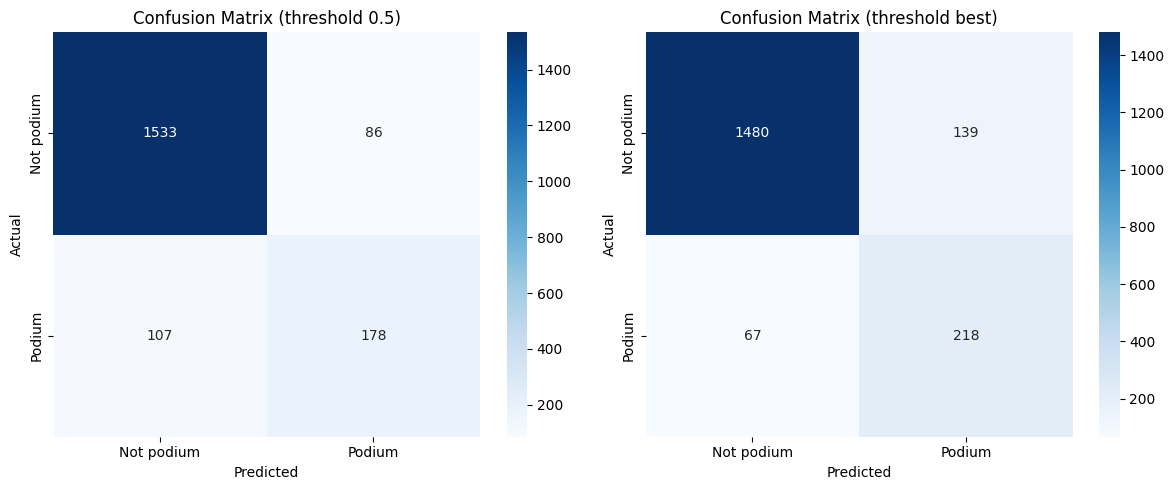

In [40]:
# ============================================================
# CONFUSION MATRIX
# ============================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Standard terskel
cm_05 = confusion_matrix(y_test, y_pred_05)
sns.heatmap(
    cm_05, annot=True, fmt="d",
    cmap="Blues", ax=ax1,
    xticklabels=["Not podium", "Podium"],
    yticklabels=["Not podium", "Podium"]
)
ax1.set_title("Confusion Matrix (threshold 0.5)")
ax1.set_ylabel("Actual")
ax1.set_xlabel("Predicted")

# Custom terskel
cm_best = confusion_matrix(y_test, y_pred_best)
sns.heatmap(
    cm_best, annot=True, fmt="d",
    cmap="Blues", ax=ax2,
    xticklabels=["Not podium", "Podium"],
    yticklabels=["Not podium", "Podium"]
)
ax2.set_title("Confusion Matrix (threshold best)")
ax2.set_ylabel("Actual")
ax2.set_xlabel("Predicted")

plt.tight_layout()
plt.show()

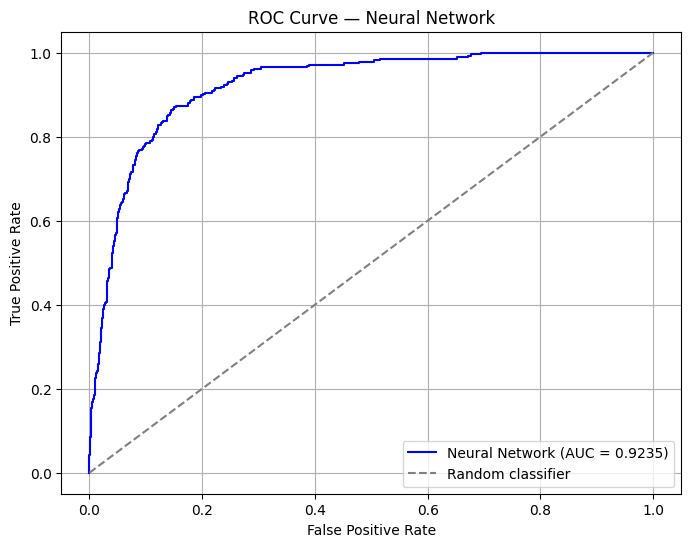

AUC Score: 0.9235
AUC = 1.0 is perfect, AUC = 0.5 is random guessing


In [41]:
# ============================================================
# ROC KURVE OG AUC
# ============================================================

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(
    fpr, tpr,
    color="blue",
    label=f"Neural Network (AUC = {auc_score:.4f})"
)
plt.plot(
    [0, 1], [0, 1],
    color="gray",
    linestyle="--",
    label="Random classifier"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Neural Network")
plt.legend()
plt.grid(True)
plt.show()

print(f"AUC Score: {auc_score:.4f}")
print("AUC = 1.0 is perfect, AUC = 0.5 is random guessing")

Trener Simple (1 layer)...
Trener Medium (3 layers)...
Trener Deep (5 layers)...




,Architecture,Epochs,Podium F1,Podium Precision,Podium Recall,AUC
0,Simple (1 layer),24,0.3333,0.7531,0.2140,0.9267
1,Medium (3 layers),12,0.4847,0.7357,0.3614,0.9235
2,Deep (5 layers),13,0.2030,0.6800,0.1193,0.9252


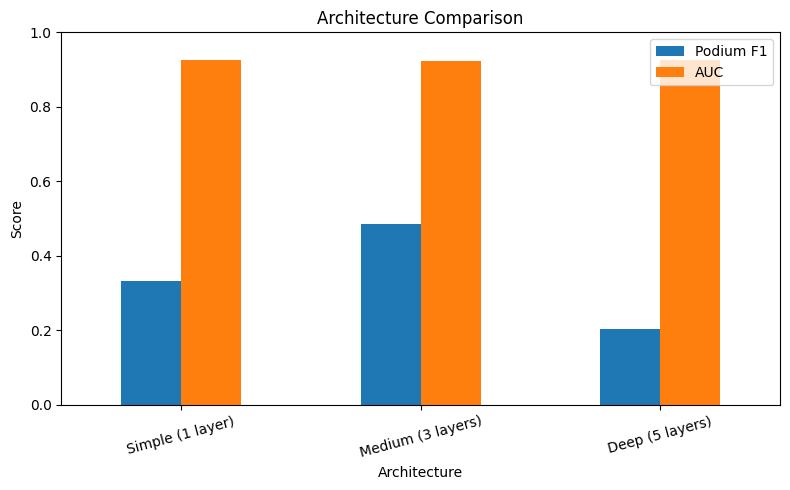

In [42]:
# ============================================================
# SAMMENLIGN ARKITEKTURER
# Enkel vs Middels vs Dyp
# ============================================================

architectures = {
    "Simple (1 layer)":   (64,),
    "Medium (3 layers)":  (128, 64, 32),
    "Deep (5 layers)":    (256, 128, 64, 32, 16)
}

arch_results = []

for name, layers in architectures.items():
    print(f"Trener {name}...")

    nn_model = MLPClassifier(
        hidden_layer_sizes=layers,
        activation="relu",
        solver="adam",
        max_iter=100,
        early_stopping=True,
        random_state=42
    )

    nn_model.fit(X_train_scaled, y_train)

    probs = nn_model.predict_proba(X_test_scaled)[:, 1]
    preds = (probs > 0.7).astype(int)
    report = classification_report(y_test, preds, output_dict=True)
    auc = roc_auc_score(y_test, probs)

    arch_results.append({
        "Architecture": name,
        "Epochs": nn_model.n_iter_,
        "Podium F1": round(report["1"]["f1-score"], 4),
        "Podium Precision": round(report["1"]["precision"], 4),
        "Podium Recall": round(report["1"]["recall"], 4),
        "AUC": round(auc, 4)
    })

arch_df = pd.DataFrame(arch_results)
print("\n")
display(arch_df)

# Plot
arch_df.set_index("Architecture")[["Podium F1", "AUC"]].plot(
    kind="bar",
    figsize=(8, 5),
    title="Architecture Comparison"
)
plt.xticks(rotation=15)
plt.ylabel("Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

,Model,Accuracy,Podium Precision,Podium Recall,Podium F1,AUC
0,Neural Network (0.5),0.898634,0.674242,0.624561,0.648452,0.923501
1,Neural Network (optimal 0.40),0.891807,0.610644,0.764912,0.679128,0.923501
2,Random Forest (notebook 04),0.910000,0.670000,0.790000,0.720000,0.950000


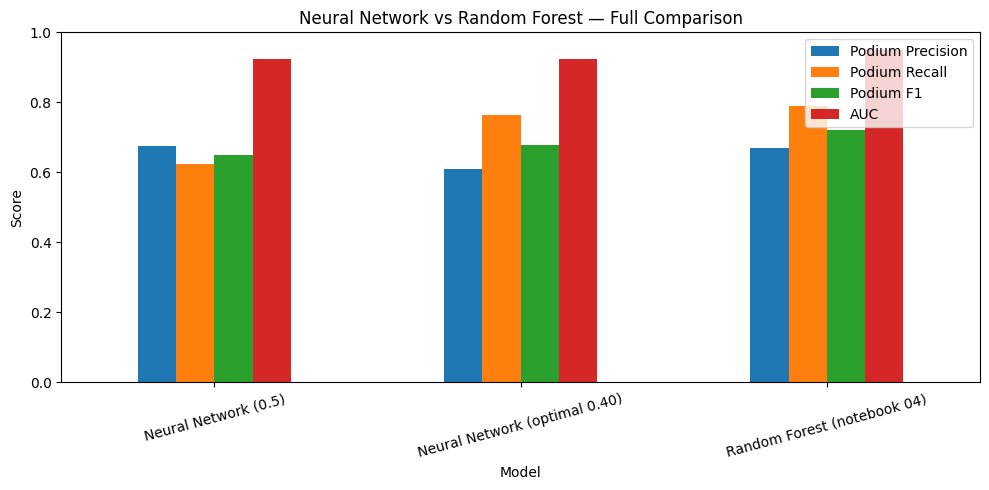

In [43]:
# ============================================================
# OPPDATERT SAMMENLIGNING MED RANDOM FOREST
# ============================================================

comparison = pd.DataFrame({
    "Model": [
        "Neural Network (0.5)",
        f"Neural Network (optimal {best_threshold:.2f})",
        "Random Forest (notebook 04)"
    ],
    "Accuracy": [
        (y_pred_05 == y_test).mean(),
        (y_pred_best == y_test).mean(),
        0.91
    ],
    "Podium Precision": [
        classification_report(y_test, y_pred_05, output_dict=True)["1"]["precision"],
        classification_report(y_test, y_pred_best, output_dict=True)["1"]["precision"],
        0.67
    ],
    "Podium Recall": [
        classification_report(y_test, y_pred_05, output_dict=True)["1"]["recall"],
        classification_report(y_test, y_pred_best, output_dict=True)["1"]["recall"],
        0.79
    ],
    "Podium F1": [
        classification_report(y_test, y_pred_05, output_dict=True)["1"]["f1-score"],
        classification_report(y_test, y_pred_best, output_dict=True)["1"]["f1-score"],
        0.72
    ],
    "AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, y_prob),
        0.95  # estimert for RF
    ]
})

display(comparison)

comparison.set_index("Model")[
    ["Podium Precision", "Podium Recall", "Podium F1", "AUC"]
].plot(
    kind="bar",
    figsize=(10, 5),
    title="Neural Network vs Random Forest — Full Comparison"
)
plt.xticks(rotation=15)
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [44]:
#Predict 2026 season table

df_2026 = df[df["season"] == 2026].copy()

for col in final_features:
    if df_2026[col].dtype.name == "category":
        df_2026[col] = df_2026[col].astype(str)

df_2026_encoded = pd.get_dummies(
    df_2026[final_features],
    columns=["constructor_name", "driver_nationality"]
)

missing_cols = set(df_encoded.columns) - set(df_2026_encoded.columns)
for col in missing_cols:
    df_2026_encoded[col] = 0

df_2026_encoded = df_2026_encoded[df_encoded.columns]

X_2026_scaled = scaler.transform(df_2026_encoded.fillna(0))

podium_probs = model_nn.predict_proba(X_2026_scaled)[:, 1]

df_2026["podium_probability"] = podium_probs
df_2026["predicted_podium"] = (podium_probs > best_threshold).astype(int)


for round_num in sorted(df_2026["round"].unique()):
    print(f"\n{'='*50}")
    print(f"ROUND {round_num} — {df_2026[df_2026['round']==round_num]['race_name'].iloc[0]}")
    print(f"{'='*50}")

    round_df = df_2026[df_2026["round"] == round_num].copy()
    round_df = round_df.sort_values("podium_probability", ascending=False)

    print(round_df[["driver_name", "constructor_name", "podium_probability", "predicted_podium", "position"]].to_string(index=False))


ROUND 1 — Australian Grand Prix
          driver_name constructor_name  podium_probability  predicted_podium  position
       George Russell         Mercedes            0.688226                 1         1
       Max Verstappen         Red Bull            0.647190                 1         6
Andrea Kimi Antonelli         Mercedes            0.597185                 1         2
         Lando Norris          McLaren            0.395519                 0         5
        Oscar Piastri          McLaren            0.341719                 0        21
      Charles Leclerc          Ferrari            0.187509                 0         3
          Liam Lawson       RB F1 Team            0.186182                 0        13
         Isack Hadjar         Red Bull            0.168539                 0        20
       Lewis Hamilton          Ferrari            0.137633                 0         4
         Carlos Sainz         Williams            0.102623                 0        15
       Arv

C:\Users\Ander\AppData\Local\Temp\ipykernel_13540\2495102395.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_2026_encoded[col] = 0
c:\Users\Ander\Desktop\F1-project\.venv\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [45]:
season_ranking = (
    df_2026.groupby(["driver_id", "driver_name"])
    .agg(
        avg_podium_prob    = ("podium_probability", "mean"),
        predicted_podiums  = ("predicted_podium", "sum"),
        actual_podiums     = ("podium", "sum"),
        actual_points      = ("points", "sum")
    )
    .reset_index()
    .sort_values("avg_podium_prob", ascending=False)
    .reset_index(drop=True)
)

season_ranking.index += 1 

print("2026 SESONG — PREDIKERT RANGERING 1-20")
print("="*60)
print(season_ranking[[
    "driver_name",
    "avg_podium_prob",
    "predicted_podiums",
    "actual_podiums",
    "actual_points"
]].to_string())

2026 SESONG — PREDIKERT RANGERING 1-20
              driver_name  avg_podium_prob  predicted_podiums  actual_podiums  actual_points
1          George Russell         0.742089                  3               2           55.0
2   Andrea Kimi Antonelli         0.655490                  3               3           68.0
3          Max Verstappen         0.572785                  3               0           12.0
4            Lando Norris         0.363961                  0               0           20.0
5           Oscar Piastri         0.255109                  0               1           18.0
6         Charles Leclerc         0.223032                  0               2           42.0
7          Lewis Hamilton         0.198760                  0               1           35.0
8             Liam Lawson         0.138734                  0               0            8.0
9            Isack Hadjar         0.137152                  0               0            4.0
10           Carlos Sainz      

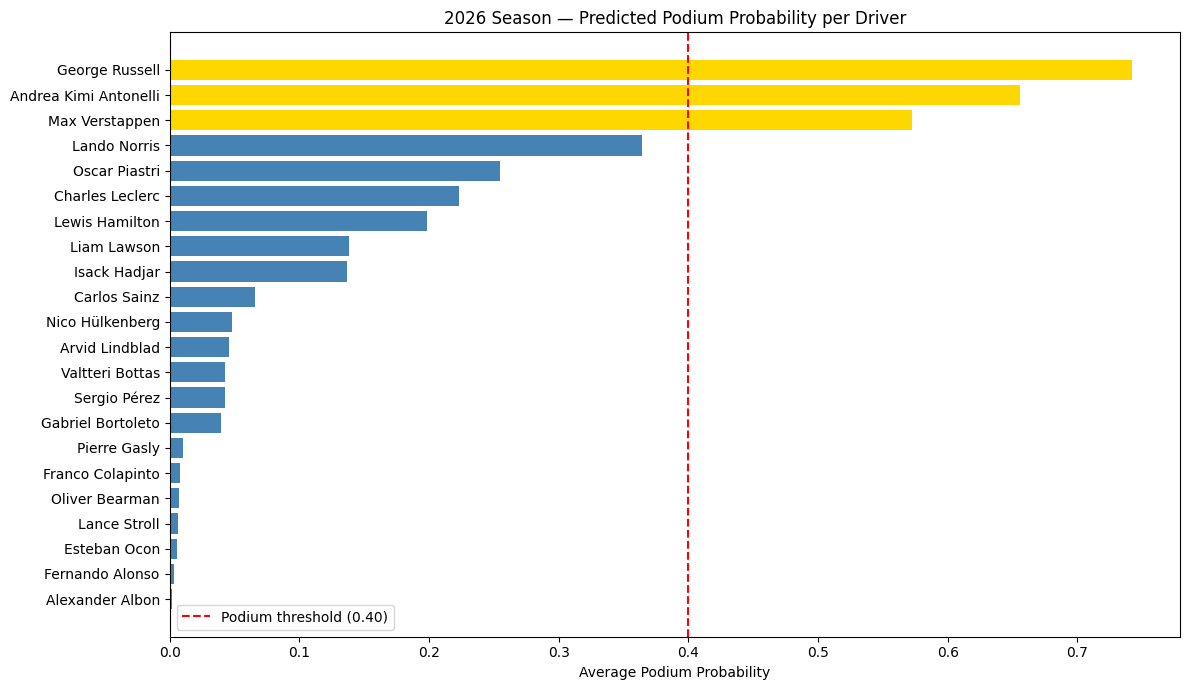

In [46]:

plt.figure(figsize=(12, 7))

colors = ["gold" if p > best_threshold else "steelblue"
          for p in season_ranking["avg_podium_prob"]]

plt.barh(
    season_ranking["driver_name"],
    season_ranking["avg_podium_prob"],
    color=colors
)

plt.axvline(
    x=best_threshold,
    color="red",
    linestyle="--",
    label=f"Podium threshold ({best_threshold:.2f})"
)

plt.xlabel("Average Podium Probability")
plt.title("2026 Season — Predicted Podium Probability per Driver")
plt.gca().invert_yaxis()
plt.legend()
plt.tight_layout()
plt.show()